In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
np.random.seed(42)

# Number of samples
n = 1000

# Generate input parameters
P = np.random.uniform(100, 1000, n)       # Load in Newton
L = np.random.uniform(0.5, 2.0, n)        # Length in metre
b = np.random.uniform(0.03, 0.10, n)      # Width in metre
h = np.random.uniform(0.04, 0.12, n)      # Height in metre

# Young's modulus of steel
E = 200e9

# Moment of inertia
I = (b * h**3) / 12

# Cantilever beam deflection
deflection = (P * L**3) / (3 * E * I)

# Convert metre into millimetre
deflection_mm = deflection * 1000

# Create dataset
data = pd.DataFrame({
    "Load_N": P,
    "Length_m": L,
    "Width_m": b,
    "Height_m": h,
    "Deflection_mm": deflection_mm
})

# Save dataset
data.to_csv("cantilever_beam_dataset.csv", index=False)

print("Dataset generated successfully!")
print(data.head())
print("Dataset size:", data.shape)


Dataset generated successfully!
       Load_N  Length_m   Width_m  Height_m  Deflection_mm
0  437.086107  0.777699  0.048319  0.093816       0.103057
1  955.642876  1.312851  0.047289  0.103735       0.819307
2  758.794548  1.809419  0.093438  0.060037       4.446133
3  638.792636  1.598337  0.047468  0.089990       1.508032
4  240.416776  1.709842  0.049036  0.085740       0.777674
Dataset size: (1000, 5)


In [5]:

# Import Machine Learning libraries

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

print("Machine Learning libraries imported successfully!")


Machine Learning libraries imported successfully!


In [6]:

# Prepare data for Machine Learning

data["Beam_Factor"] = (
    data["Load_N"] * data["Length_m"]**3 /
    (data["Width_m"] * data["Height_m"]**3)
)

X = data[["Beam_Factor"]]
y = data["Deflection_mm"]

# Split dataset: 80% training, 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Create Linear Regression model

model = LinearRegression(fit_intercept=False)

# Train model

model.fit(X_train, y_train)

print("AI model trained successfully!")


AI model trained successfully!


In [7]:

# Predict beam deflection

predictions = model.predict(X_test)

# Evaluate model performance

mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Model Evaluation Results")
print("-------------------------")
print("Mean Absolute Error:", mae, "mm")
print("R2 Score:", r2)


Model Evaluation Results
-------------------------
Mean Absolute Error: 5.84007668613662e-16 mm
R2 Score: 1.0


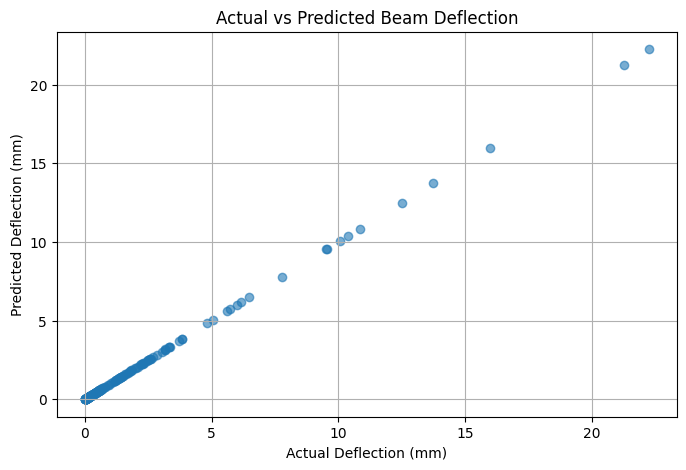

In [8]:

# Actual vs Predicted Deflection Graph

plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions, alpha=0.6)

plt.xlabel("Actual Deflection (mm)")
plt.ylabel("Predicted Deflection (mm)")
plt.title("Actual vs Predicted Beam Deflection")

plt.grid(True)
plt.show()


In [9]:

# New beam parameters

load = 500       # Newton
length = 1.0     # metre
width = 0.05     # metre
height = 0.08    # metre

# Calculate beam factor
beam_factor = (
    load * length**3 /
    (width * height**3)
)

# Predict deflection
new_prediction = model.predict(
    pd.DataFrame({"Beam_Factor": [beam_factor]})
)

print("NEW BEAM PREDICTION")
print("-------------------")
print("Applied Load:", load, "N")
print("Beam Length:", length, "m")
print("Predicted Deflection:", round(new_prediction[0], 4), "mm")


NEW BEAM PREDICTION
-------------------
Applied Load: 500 N
Beam Length: 1.0 m
Predicted Deflection: 0.3906 mm


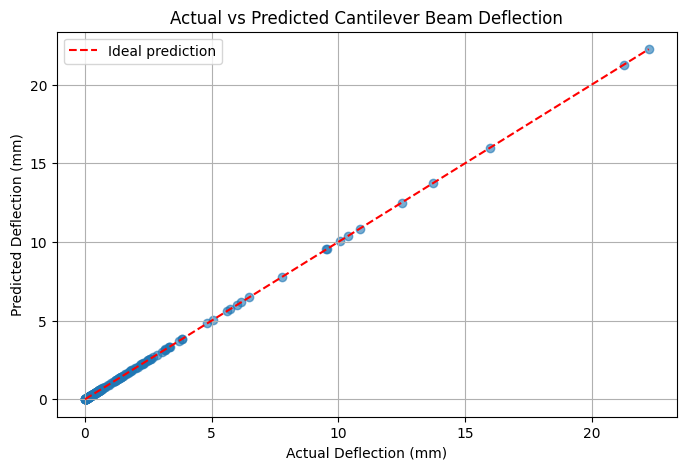

In [10]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions, alpha=0.6)

# Ideal prediction line
minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--',
    label="Ideal prediction"
)

plt.xlabel("Actual Deflection (mm)")
plt.ylabel("Predicted Deflection (mm)")
plt.title("Actual vs Predicted Cantilever Beam Deflection")
plt.legend()
plt.grid(True)
plt.show()


In [11]:

from sklearn.ensemble import RandomForestRegressor

# Select original mechanical input parameters
X = data[["Load_N", "Length_m", "Width_m", "Height_m"]]
y = data["Deflection_mm"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [12]:

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Model Results")
print("---------------------------")
print("Mean Absolute Error:", round(rf_mae, 6), "mm")
print("R2 Score:", round(rf_r2, 4))


Random Forest Model Results
---------------------------
Mean Absolute Error: 0.287921 mm
R2 Score: 0.9609


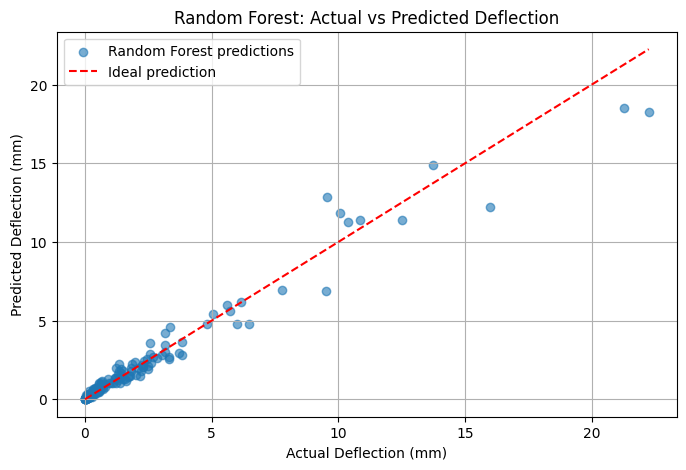

In [13]:

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.6,
    label="Random Forest predictions"
)

minimum = min(y_test.min(), rf_predictions.min())
maximum = max(y_test.max(), rf_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Ideal prediction"
)

plt.xlabel("Actual Deflection (mm)")
plt.ylabel("Predicted Deflection (mm)")
plt.title("Random Forest: Actual vs Predicted Deflection")
plt.legend()
plt.grid(True)
plt.show()


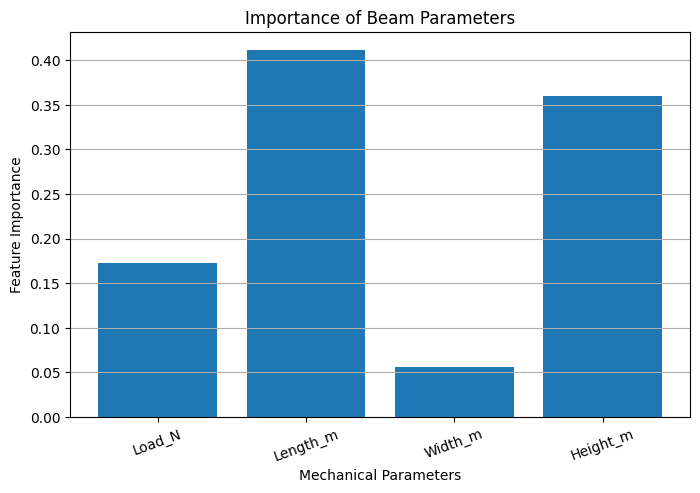

  Parameter  Importance
0    Load_N    0.173055
1  Length_m    0.410993
2   Width_m    0.056488
3  Height_m    0.359463


In [14]:

importance = rf_model.feature_importances_

plt.figure(figsize=(8, 5))

plt.bar(
    X.columns,
    importance
)

plt.xlabel("Mechanical Parameters")
plt.ylabel("Feature Importance")
plt.title("Importance of Beam Parameters")
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.show()

print(pd.DataFrame({
    "Parameter": X.columns,
    "Importance": importance
}))


In [15]:

import joblib
import json

# Save trained AI model
joblib.dump(rf_model, "cantilever_beam_model.pkl")

# Save model evaluation results
results = {
    "Model": "Random Forest Regression",
    "Mean Absolute Error": float(rf_mae),
    "R2 Score": float(rf_r2),
    "Dataset Samples": 1000
}

with open("model_results.json", "w") as file:
    json.dump(results, file, indent=4)

print("AI model saved successfully!")
print("Model results saved successfully!")


AI model saved successfully!
Model results saved successfully!


In [16]:

new_beam = pd.DataFrame({
    "Load_N": [500],
    "Length_m": [1.0],
    "Width_m": [0.05],
    "Height_m": [0.08]
})

prediction = rf_model.predict(new_beam)

print("FINAL AI PREDICTION")
print("Predicted deflection:", round(prediction[0], 4), "mm")


FINAL AI PREDICTION
Predicted deflection: 0.4117 mm
